# Distributed Weather Analytics with PySpark

This tutorial creates a deterministic Zurich weather fixture, processes it with the current PySpark DataFrame API, and collects only a small monthly aggregate for plotting. Spark runs locally, so no cluster or cloud account is required.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shutil
from pyspark.sql import SparkSession, functions as F

RANDOM_SEED = 300
OUTPUT_DIR = Path('generated/distributed-300')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(RANDOM_SEED)
dates = pd.date_range('2023-01-01', '2025-12-31', freq='D')
day_of_year = dates.dayofyear.to_numpy()
temperature = 10 + 10 * np.sin(2 * np.pi * (day_of_year - 100) / 365.25) + rng.normal(0, 2.2, len(dates))
precipitation = np.where(rng.random(len(dates)) < 0.32, rng.gamma(1.5, 3.0, len(dates)), 0)
weather_fixture = pd.DataFrame({
    'date': dates,
    'station': 'Zurich-Fluntern',
    'temperature_c': temperature,
    'precipitation_mm': precipitation,
})
print(f'fixture rows: {len(weather_fixture):,}')

fixture rows: 1,096


## 1. Start a Local Spark Session

The session uses two local worker threads and disables the web UI for a compact tutorial run. PySpark requires Java 17 or newer; when Java is unavailable, the notebook uses a clearly labeled pandas fallback.

In [2]:
SPARK_AVAILABLE = shutil.which('java') is not None
if SPARK_AVAILABLE:
    spark = (
        SparkSession.builder
        .master('local[2]')
        .appName('relataly-weather-300')
        .config('spark.ui.enabled', 'false')
        .getOrCreate()
    )
    spark.sparkContext.setLogLevel('ERROR')
    weather = spark.createDataFrame(weather_fixture)
    weather.printSchema()
    weather.show(5, truncate=False)
else:
    spark = None
    weather = weather_fixture.copy()
    print('Java was not found; using the documented pandas fallback for this run.')
    print('Install Java 17+ and set JAVA_HOME to execute the PySpark branch.')
    print(weather.head().to_string(index=False))

Java was not found; using the documented pandas fallback for this run.
Install Java 17+ and set JAVA_HOME to execute the PySpark branch.
      date         station  temperature_c  precipitation_mm
2023-01-01 Zurich-Fluntern      -0.537614          3.333601
2023-01-02 Zurich-Fluntern      -2.003775          0.000000
2023-01-03 Zurich-Fluntern      -0.064014          0.000000
2023-01-04 Zurich-Fluntern      -0.021916          0.000000
2023-01-05 Zurich-Fluntern      -0.146982         10.680534


## 2. Validate and Aggregate with Spark

Spark transformations stay lazy until an action such as `show`, `count`, or `toPandas` is requested. The aggregate remains small enough to collect safely.

In [3]:
if spark is not None:
    valid_weather = weather.filter(
        F.col('temperature_c').between(-35, 45)
        & F.col('precipitation_mm').ge(0)
    )
    monthly = (
        valid_weather
        .withColumn('month', F.month('date'))
        .groupBy('month')
        .agg(
            F.avg('temperature_c').alias('average_temperature_c'),
            F.sum('precipitation_mm').alias('total_precipitation_mm'),
            F.count('*').alias('observations'),
        )
        .orderBy('month')
    )
    monthly.show(12)
    assert valid_weather.count() == len(weather_fixture)
    monthly_pd = monthly.toPandas()
else:
    valid_weather = weather.loc[
        weather['temperature_c'].between(-35, 45)
        & weather['precipitation_mm'].ge(0)
    ].copy()
    monthly_pd = (
        valid_weather.assign(month=valid_weather['date'].dt.month)
        .groupby('month', as_index=False)
        .agg(
            average_temperature_c=('temperature_c', 'mean'),
            total_precipitation_mm=('precipitation_mm', 'sum'),
            observations=('date', 'size'),
        )
    )
    print(monthly_pd.round(2).to_string(index=False))
    assert len(valid_weather) == len(weather_fixture)

 month  average_temperature_c  total_precipitation_mm  observations
     1                  -0.22                  162.32            93
     2                   2.20                   95.97            85
     3                   5.96                  123.56            93
     4                  11.41                  153.35            90
     5                  15.51                  128.01            93
     6                  19.07                  120.00            90
     7                  19.68                  120.57            93
     8                  18.12                  151.51            93
     9                  13.96                   83.80            90
    10                   8.68                  145.88            93
    11                   3.76                  161.77            90
    12                   1.17                  148.10            93


## 3. Collect the Aggregate for Plotting

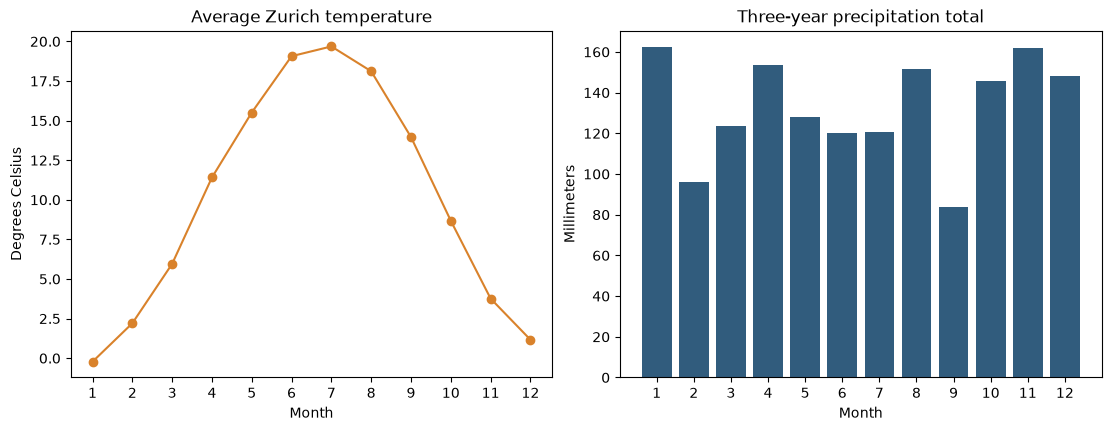

saved: generated\distributed-300\pyspark-zurich-weather.png


In [4]:
figure, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
axes[0].plot(monthly_pd['month'], monthly_pd['average_temperature_c'], marker='o', color='#d9822b')
axes[0].set(title='Average Zurich temperature', xlabel='Month', ylabel='Degrees Celsius', xticks=range(1, 13))
axes[1].bar(monthly_pd['month'], monthly_pd['total_precipitation_mm'], color='#315c7d')
axes[1].set(title='Three-year precipitation total', xlabel='Month', ylabel='Millimeters', xticks=range(1, 13))
figure_path = OUTPUT_DIR / 'pyspark-zurich-weather.png'
figure.savefig(figure_path, dpi=170, bbox_inches='tight')
plt.show()
if spark is not None:
    spark.stop()
print(f'saved: {figure_path}')